# What makes Munich cycle?

Munich has automatic bike counters that log every passing cyclist in 15-minute intervals, along with the day's weather. This notebook uses the city's 2025 open data to answer four questions:

1. How much does cycling change across the year, and between counting stations?
2. Which stations carry commuters, and which carry leisure riders?
3. How much do rain, temperature, sunshine, holidays and events move the numbers?
4. Can a day's cycling volume be predicted from the calendar and the weather forecast?

**Data:** [Raddauerzählstellen München](https://opendata.muenchen.de), daily totals for January to December 2025 (5 stations), plus 15-minute counts for June and December 2025.

In [1]:
import glob
import warnings
from pathlib import Path

import holidays
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

STATIONS = ["Erhardt", "Olympia", "Hirsch", "Arnulf", "Kreuther"]
COLORS = {"Erhardt": "#0f766e", "Olympia": "#2563eb", "Hirsch": "#d97706", "Arnulf": "#7c3aed", "Kreuther": "#6b7280"}
GREY, LIGHT, RED = "#6b7280", "#d1d5db", "#dc2626"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10,
})
thousands = mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k" if abs(x) >= 1000 else f"{x:.0f}")

## 1. Loading and checking the data

In [2]:
COLUMNS = {"zaehlstelle": "station", "richtung_1": "dir_1", "richtung_2": "dir_2", "gesamt": "total",
           "min-temp": "temp_min", "max-temp": "temp_max", "niederschlag": "rain_mm",
           "bewoelkung": "cloud_pct", "sonnenstunden": "sun_hours"}

daily = pd.concat(
    [pd.read_csv(f, encoding="utf-8-sig") for f in sorted(glob.glob(str(ROOT / "data/raw/rad_2025_*_tage.csv")))],
    ignore_index=True,
).rename(columns=COLUMNS)
daily["date"] = pd.to_datetime(daily["datum"], format="%Y.%m.%d")
daily = daily.drop(columns=["datum", "uhrzeit_start", "uhrzeit_ende"]).sort_values(["station", "date"])

print(f"{len(daily):,} station-days, {daily['date'].min():%d %b} to {daily['date'].max():%d %b %Y}")
print(f"Missing values: {daily.isna().sum().sum()} | Zero-count days: {(daily['total'] == 0).sum()}")
print(f"Rows where direction 1 + direction 2 != total: {(daily['dir_1'] + daily['dir_2'] != daily['total']).sum()}")
print(f"Days with differing weather across stations: {(daily.groupby('date')['rain_mm'].nunique() > 1).sum()}")
daily.groupby("station")["date"].agg(first_day="min", last_day="max", days="count").loc[STATIONS]

1,552 station-days, 01 Jan to 31 Dec 2025
Missing values: 0 | Zero-count days: 0
Rows where direction 1 + direction 2 != total: 0
Days with differing weather across stations: 0


,first_day,last_day,days
station,,,
Erhardt,2025-01-01,2025-12-31,365
Olympia,2025-01-01,2025-12-31,365
Hirsch,2025-01-01,2025-12-31,365
Arnulf,2025-01-01,2025-12-31,365
Kreuther,2025-10-01,2025-12-31,92


In [3]:
def load_15min(month):
    df = pd.read_csv(ROOT / f"data/raw/rad_2025_{month}_15min.csv", encoding="utf-8-sig").rename(columns=COLUMNS)
    df["timestamp"] = pd.to_datetime(df["datum"] + " " + df["uhrzeit_start"], format="%Y.%m.%d %H:%M")
    return df[["timestamp", "station", "dir_1", "dir_2", "total"]]

quarter = pd.concat([load_15min("06"), load_15min("12")], ignore_index=True)

# Cross-check: the 15-minute counts should add up to the daily totals.
check = (quarter.assign(date=quarter["timestamp"].dt.normalize())
         .groupby(["station", "date"])["total"].sum()
         .to_frame("sum_15min")
         .join(daily.set_index(["station", "date"])["total"]))
print(f"Station-days compared: {len(check)} | mismatches: {(check['sum_15min'] != check['total']).sum()}")

direction_share = (daily.groupby("station")[["dir_1", "total"]].sum().pipe(lambda t: t["dir_1"] / t["total"]))
print("\nShare of traffic counted in direction 1:")
print(direction_share.loc[STATIONS].map("{:.0%}".format).to_string())

Station-days compared: 275 | mismatches: 0

Share of traffic counted in direction 1:
station
Erhardt     55%
Olympia     51%
Hirsch      50%
Arnulf      94%
Kreuther    55%


**What I found**

- The data is clean: no gaps, no zero days, the two directions always add up to the total, and the 15-minute counts match the daily totals exactly.
- The weather columns are identical for every station on a given day, so they come from one city-wide weather station. That's fine for a city as compact as Munich, but local showers won't show up.
- **Kreuther only has data from October**, presumably because the counter was installed or reconnected then. I show it in descriptive charts but leave it out of the models, since it has no summer to learn from.
- **Arnulf counts 94% of its traffic in one direction**, while every other station is close to 50/50. That's either a one-way cycle lane or a counter that only covers one side of the street. Either way, Arnulf undercounts relative to the others, so I compare stations by *patterns* (ratios, shapes) rather than raw totals.

## 2. The cycling year

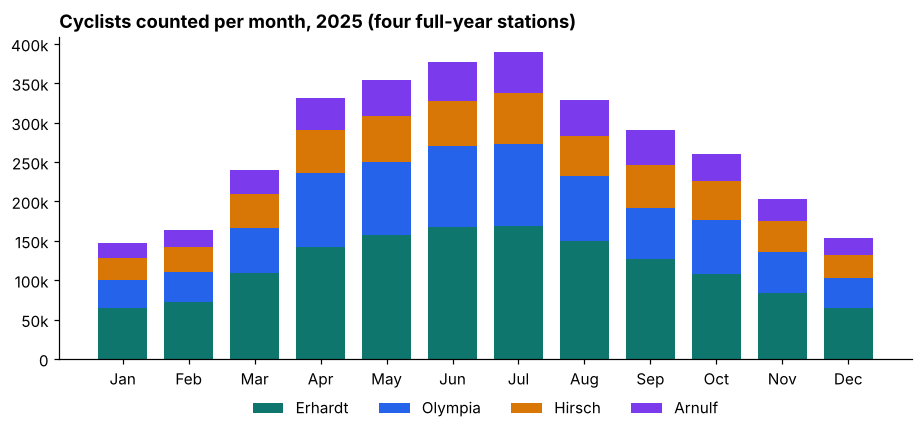

Peak month: July (389,180) | Lowest: January (147,564) | Ratio: 2.6x


In [4]:
monthly = daily.pivot_table(index=daily["date"].dt.to_period("M"), columns="station", values="total", aggfunc="sum")
city = daily[daily["station"] != "Kreuther"].groupby(daily["date"].dt.to_period("M"))["total"].sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(monthly))
for s in [s for s in STATIONS if s != "Kreuther"]:
    ax.bar(monthly.index.strftime("%b"), monthly[s], bottom=bottom, color=COLORS[s], label=s, width=0.75)
    bottom += monthly[s].values
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Cyclists counted per month, 2025 (four full-year stations)")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.savefig(IMG / "01_monthly.png")
plt.show()

print(f"Peak month: {city.idxmax().strftime('%B')} ({city.max():,.0f}) | Lowest: {city.idxmin().strftime('%B')} ({city.min():,.0f}) "
      f"| Ratio: {city.max() / city.min():.1f}x")

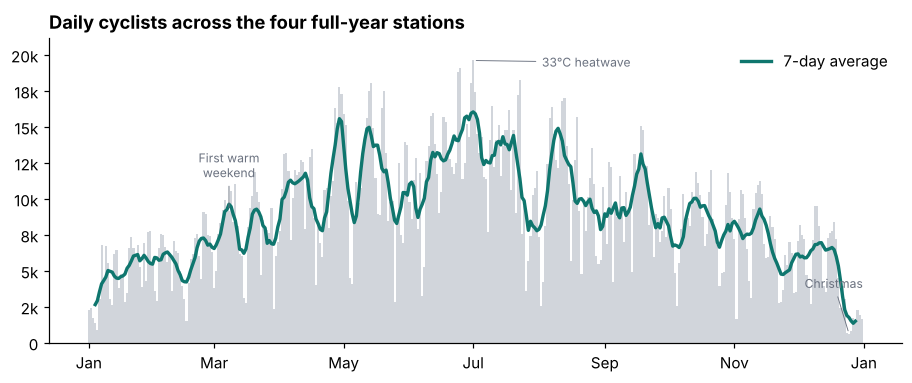

In [5]:
full = daily[daily["station"] != "Kreuther"]
city_daily = full.groupby("date").agg(total=("total", "sum"), rain_mm=("rain_mm", "first"), temp_max=("temp_max", "first"))
smooth = city_daily["total"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(city_daily.index, city_daily["total"], color=LIGHT, width=1)
ax.plot(smooth.index, smooth, color="#0f766e", lw=2.2, label="7-day average")
for day, label, offset in [("2025-03-08", "First warm\nweekend", (0, 22)), ("2025-07-01", "33°C heatwave", (45, -4)),
                          ("2025-12-25", "Christmas", (-10, 30))]:
    ts = pd.Timestamp(day)
    ax.annotate(label, (ts, city_daily.loc[ts, "total"]), xytext=offset, textcoords="offset points",
                ha="center" if offset[0] <= 0 else "left", fontsize=8, color=GREY,
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.6))
ax.set_ylim(0, city_daily["total"].max() * 1.08)
ax.yaxis.set_major_formatter(thousands)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Daily cyclists across the four full-year stations")
ax.legend(frameon=False, loc="upper right")
fig.savefig(IMG / "02_daily.png")
plt.show()

July had **2.6 times as many cyclists as January**. The daily bars show that the season isn't a smooth curve: individual days swing wildly with the weather, and the first warm weekends in March already reach summer-like levels. Christmas week is the deepest trough of the year.

## 3. Commuter or leisure? Each station's personality

Two simple measures separate commuter routes from leisure routes:

- **Weekend ratio:** average weekend day divided by average weekday. Commuter routes empty out on weekends.
- **Peak share:** share of weekday traffic in the two rush hours (7-9 and 16-18), from the 15-minute data.

In [6]:
daily["weekend"] = daily["date"].dt.dayofweek >= 5
weekend_ratio = daily.groupby(["station", "weekend"])["total"].mean().unstack().pipe(lambda t: t[True] / t[False])

q = quarter.assign(hour=quarter["timestamp"].dt.hour, weekend=quarter["timestamp"].dt.dayofweek >= 5)
wk = q[~q["weekend"]]
peak_share = wk[wk["hour"].isin([7, 8, 16, 17])].groupby("station")["total"].sum() / wk.groupby("station")["total"].sum()

profile = pd.DataFrame({"weekend_ratio": weekend_ratio, "rush_hour_share": peak_share}).loc[STATIONS]
profile["type"] = np.where(profile["weekend_ratio"] < 0.7, "Commuter", "Mixed / leisure")
profile.style.format({"weekend_ratio": "{:.2f}", "rush_hour_share": "{:.0%}"})

,weekend_ratio,rush_hour_share,type
station,,,
Erhardt,0.80,31%,Mixed / leisure
Olympia,0.85,30%,Mixed / leisure
Hirsch,0.48,41%,Commuter
Arnulf,0.66,33%,Commuter
Kreuther,0.51,40%,Commuter


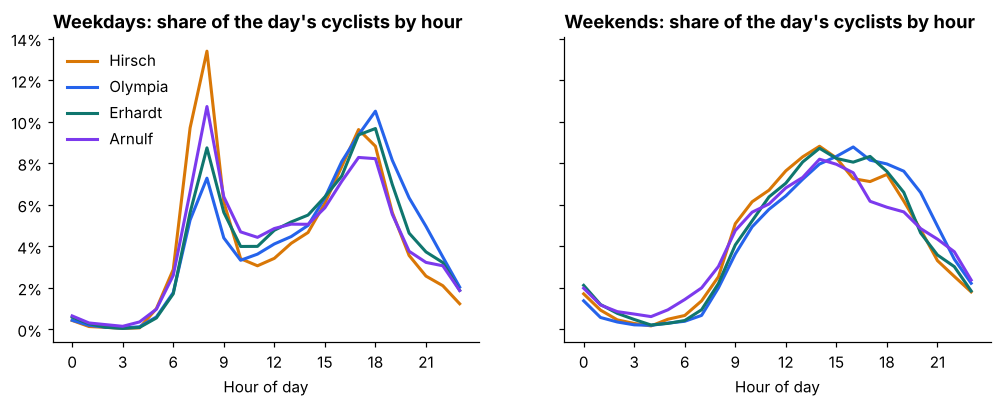

In [7]:
hourly = (q.groupby(["station", "weekend", "hour", q["timestamp"].dt.month.rename("month")])["total"].sum()
          .groupby(["station", "weekend", "hour"]).sum())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, wkd, title in [(axes[0], False, "Weekdays"), (axes[1], True, "Weekends")]:
    for s in ["Hirsch", "Olympia", "Erhardt", "Arnulf"]:
        h = hourly.loc[(s, wkd)]
        ax.plot(h.index, h / h.sum(), color=COLORS[s], lw=2, label=s)
    ax.set_title(f"{title}: share of the day's cyclists by hour")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Hour of day")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].legend(frameon=False)
fig.savefig(IMG / "03_hourly_profiles.png")
plt.show()

- **Hirsch and Kreuther are commuter routes.** Weekend traffic is only about half of weekday traffic, and about 40% of weekday riding happens in the four rush hours. Hirsch's 8:00 hour alone carries 13% of the day.
- **Olympia and Erhardt are mixed routes** with strong weekend use (80-85% of weekday levels). On weekends their peak moves to a broad early-afternoon hump, which is leisure riding in the Olympiapark and along the Isar.
- **Arnulf also leans commuter** (weekend ratio 0.66, clear morning and evening peaks). Its dominant direction carries both the morning and the evening peak, so the imbalance is more likely a one-way lane or a one-sided counter than an inbound-only commute.

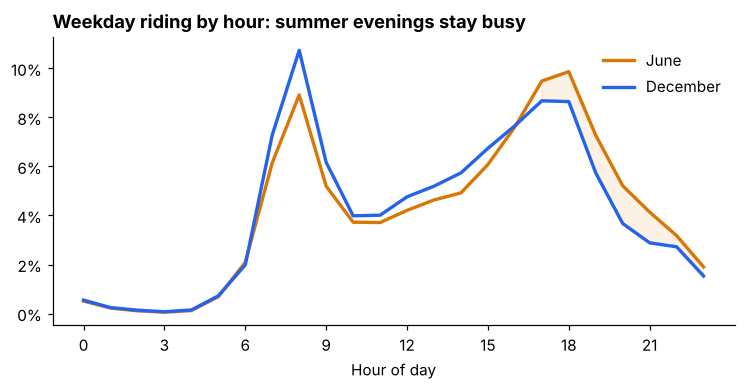

Share of weekday cycling between 18:00 and 23:00: June 30%, December 24%


In [8]:
season = (q.assign(month=q["timestamp"].dt.month.map({6: "June", 12: "December"}))
          [~q["weekend"]].groupby(["month", "hour"])["total"].sum().unstack(0))
season = season / season.sum()

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(season.index, season["June"], color="#d97706", lw=2.2, label="June")
ax.plot(season.index, season["December"], color="#2563eb", lw=2.2, label="December")
ax.fill_between(season.index, season["June"], season["December"],
                where=season["June"] > season["December"], color="#d97706", alpha=0.1)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Weekday riding by hour: summer evenings stay busy")
ax.legend(frameon=False)
fig.savefig(IMG / "04_june_vs_december.png")
plt.show()

evening = season.loc[18:22].sum()
print(f"Share of weekday cycling between 18:00 and 23:00: June {evening['June']:.0%}, December {evening['December']:.0%}")

In December, cycling is concentrated in the commute. In June, 30% of weekday riding happens after 18:00, against 24% in December. Part of the extra summer volume is **evening leisure riding on top of the commute**, not just more commuters.

## 4. What moves the numbers: weather, holidays and events

Raw comparisons ("rainy days are quieter") mix up several effects. Rain is more common in some months, and holidays fall on particular days. To separate them I fit one regression on the log of daily counts:

`log(cyclists) ~ station × day type + weekday + public holiday + school holiday + Christmas period + max temperature (+ squared) + log(1 + rain) + sunshine hours`

On the log scale, each coefficient reads as a percentage change with everything else held constant.

**Calendar inputs:** Bavarian public holidays come from the `holidays` package, plus 15 August (Mariä Himmelfahrt), which is a holiday in Munich but not in every Bavarian municipality. School holiday dates are the 2025 Bavarian ones published by the state ministry of education.

In [9]:
public_holidays = set(holidays.Germany(subdiv="BY", years=2025)) | {pd.Timestamp("2025-08-15").date()}
SCHOOL_HOLIDAYS = [("2025-01-01", "2025-01-03"), ("2025-03-03", "2025-03-07"), ("2025-04-14", "2025-04-25"),
                   ("2025-06-10", "2025-06-20"), ("2025-08-01", "2025-09-15"), ("2025-11-03", "2025-11-07"),
                   ("2025-11-19", "2025-11-19"), ("2025-12-22", "2025-12-31")]

def add_calendar(df):
    df = df.copy()
    df["holiday"] = df["date"].dt.date.isin(public_holidays)
    df["school_holiday"] = False
    for start, end in SCHOOL_HOLIDAYS:
        df.loc[df["date"].between(start, end), "school_holiday"] = True
    df["christmas"] = df["date"].between("2025-12-24", "2025-12-31") | df["date"].between("2025-01-01", "2025-01-06")
    df["weekday"] = df["date"].dt.day_name().str[:3]
    df["off_day"] = (df["date"].dt.dayofweek >= 5) | df["holiday"]
    df["month"] = df["date"].dt.month
    df["log_total"] = np.log(df["total"])
    return df

daily = add_calendar(daily)

**Events.** A few days at Olympia were wildly off-pattern, so I checked the event calendar:

| Date | Olympia vs normal | Explanation |
|---|---|---|
| Sun 12 Oct | 3.6× | A 10 km city run, confirmed in the event listings |
| Sat 19 Jul | 0.2× on a 29°C sunny day | *Sommernachtstraum*, a ticketed open-air festival in the Olympiapark, so the paths were closed to through traffic |
| Sat-Sun 26-27 Apr | 2.2-2.4× | Not yet explained. The *Frühlingsfest* started that weekend, but it's on the Theresienwiese, not near this counter |
| Wed 16 Jul | 1.6× on a rainy day | Not yet explained |

I exclude these five station-days from the models so they don't distort the weather effects.

In [10]:
EVENT_DAYS = pd.to_datetime(["2025-04-26", "2025-04-27", "2025-07-16", "2025-07-19", "2025-10-12"])
daily["event"] = (daily["station"] == "Olympia") & daily["date"].isin(EVENT_DAYS)

FORMULA = ("log_total ~ C(station) * off_day + C(weekday) + holiday + school_holiday + christmas"
           " + temp_max + I(temp_max ** 2) + np.log1p(rain_mm) + sun_hours")
model_data = daily[(daily["station"] != "Kreuther") & ~daily["event"]]
model = smf.ols(FORMULA, data=model_data).fit(cov_type="HC3")
print(f"R² = {model.rsquared:.3f} on {int(model.nobs)} station-days")

R² = 0.916 on 1455 station-days


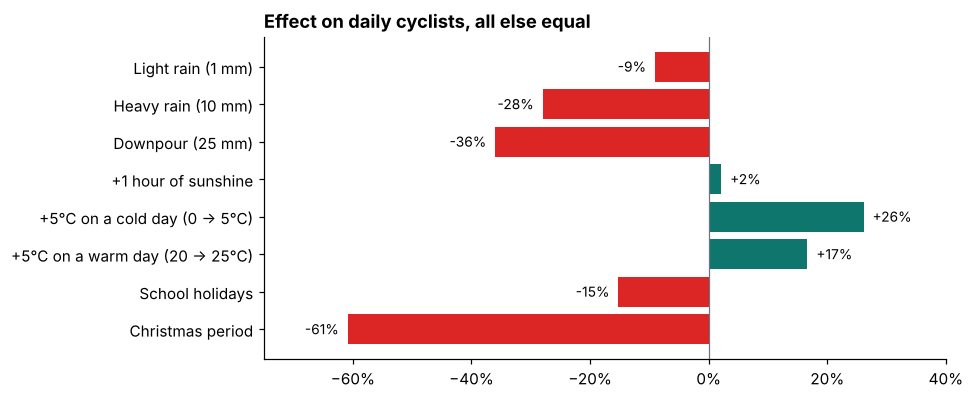

,effect
Light rain (1 mm),-9.1%
Heavy rain (10 mm),-28.0%
Downpour (25 mm),-36.0%
+1 hour of sunshine,+2.1%
+5°C on a cold day (0 → 5°C),+26.1%
+5°C on a warm day (20 → 25°C),+16.7%
School holidays,-15.2%
Christmas period,-60.9%


In [11]:
p = model.params
rain = lambda mm: np.exp(p["np.log1p(rain_mm)"] * np.log1p(mm)) - 1
temp = lambda t0, t1: np.exp(p["temp_max"] * (t1 - t0) + p["I(temp_max ** 2)"] * (t1**2 - t0**2)) - 1

effects = pd.Series({
    "Light rain (1 mm)": rain(1),
    "Heavy rain (10 mm)": rain(10),
    "Downpour (25 mm)": rain(25),
    "+1 hour of sunshine": np.exp(p["sun_hours"]) - 1,
    "+5°C on a cold day (0 → 5°C)": temp(0, 5),
    "+5°C on a warm day (20 → 25°C)": temp(20, 25),
    "School holidays": np.exp(p["school_holiday[T.True]"]) - 1,
    "Christmas period": np.exp(p["christmas[T.True]"]) - 1,
})

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [RED if v < 0 else "#0f766e" for v in effects]
ax.barh(effects.index[::-1], effects.values[::-1], color=colors[::-1])
ax.axvline(0, color=GREY, lw=0.8)
for y, v in enumerate(effects.values[::-1]):
    ax.text(v + (0.015 if v >= 0 else -0.015), y, f"{v:+.0%}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(-0.75, 0.4)
ax.set_title("Effect on daily cyclists, all else equal")
fig.savefig(IMG / "05_effects.png")
plt.show()
effects.map("{:+.1%}".format).to_frame("effect")

- **Rain matters a lot, with diminishing returns.** One millimetre costs about 9% of riders and 10 mm about 28%, but a 25 mm downpour only about 36%. Once it's properly wet, people who'd stay home already have.
- **Warmth helps more when it's cold.** Going from 0 to 5°C adds about 26%, while 20 to 25°C adds about 17%.
- **Each hour of sunshine adds about 2%**, on top of temperature.
- **School holidays cut cycling by about 15%**: families travel, and the school run disappears.
- **The Christmas period cuts it by about 60%**, the largest single effect in the data.

In [12]:
by_station = []
for s in ["Erhardt", "Olympia", "Hirsch", "Arnulf"]:
    m = smf.ols(FORMULA.replace("C(station) * off_day", "off_day"),
                data=model_data[model_data["station"] == s]).fit()
    by_station.append({"station": s, "effect of 10 mm rain": np.exp(m.params["np.log1p(rain_mm)"] * np.log1p(10)) - 1,
                       "effect of school holidays": np.exp(m.params["school_holiday[T.True]"]) - 1})
pd.DataFrame(by_station).set_index("station").style.format("{:+.0%}")

,effect of 10 mm rain,effect of school holidays
station,,
Erhardt,-28%,-16%
Olympia,-31%,-19%
Hirsch,-29%,-17%
Arnulf,-24%,-8%


Run separately per station, the effects are **surprisingly similar**. 10 mm of rain costs 24-31% everywhere, and school holidays cost 16-19% at three stations. I expected commuters to ride through rain more than leisure riders, but one year of data doesn't show a clear difference. The exception is Arnulf, where school holidays barely matter (−8%), possibly because its one-sided counter misses school-run traffic.

In [13]:
rainy = model_data[model_data["rain_mm"] > 0]
lost = (rainy["total"] * (np.exp(-p["np.log1p(rain_mm)"] * np.log1p(rainy["rain_mm"])) - 1)).sum()
counted = model_data["total"].sum()
print(f"Rainy days in 2025: {rainy['date'].nunique()} of 365")
print(f"Estimated cyclists lost to rain at the four stations: {lost:,.0f} "
      f"({lost / (counted + lost):.0%} of the rain-free total)")

Rainy days in 2025: 156 of 365
Estimated cyclists lost to rain at the four stations: 238,300 (7% of the rain-free total)


Holding everything else constant, rain cost these four counters about 7% of potential trips in 2025, roughly one in fourteen. That's a useful number for the city: covered bike parking and good drainage target exactly the riders who currently switch to other transport on wet days.

## 5. Forecasting tomorrow's cyclists

A city operator might want to predict tomorrow's volume per counter, for example to plan maintenance, staff an event or check whether a counter is broken. Here the inputs are the calendar and the weather forecast.

**Test design:** an expanding window. For each month from April to December I train only on the months before it, then predict every day of that month. This mimics using the model in real time, and it's strict, since early months have very little training data.

I compare three approaches:

- **Same weekday last week** (baseline)
- **XGBoost** on the calendar and weather features
- **The regression from section 4**

In [14]:
fc = daily[(daily["station"] != "Kreuther")].copy()
fc["station_code"] = fc["station"].astype("category").cat.codes
fc["dow"] = fc["date"].dt.dayofweek
fc["doy"] = fc["date"].dt.dayofyear
FEATURES = ["station_code", "dow", "doy", "temp_max", "temp_min", "rain_mm", "sun_hours", "cloud_pct",
            "holiday", "school_holiday", "christmas", "off_day"]
last_week = fc.set_index(["station", "date"])["total"]

rows = []
for month in range(4, 13):
    train = fc[(fc["month"] < month) & ~fc["event"]]
    test = fc[fc["month"] == month].copy()
    xgb = XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, random_state=0)
    xgb.fit(train[FEATURES].astype(float), train["log_total"])
    test["XGBoost"] = np.exp(xgb.predict(test[FEATURES].astype(float)))
    test["Regression"] = np.exp(smf.ols(FORMULA, data=train).fit().predict(test))
    test["Same weekday last week"] = [last_week.get((s, d - pd.Timedelta(days=7)), np.nan)
                                      for s, d in zip(test["station"], test["date"])]
    rows.append(test)
pred = pd.concat(rows)

def wape(df, col):
    # Weighted absolute percentage error: total absolute error / total actual cyclists
    return (df[col] - df["total"]).abs().sum() / df["total"].sum()

models = ["Same weekday last week", "XGBoost", "Regression"]
scores = pd.DataFrame({m: pred.groupby("month").apply(lambda g: wape(g, m)) for m in models})
scores.loc["Apr-Dec"] = [wape(pred, m) for m in models]
scores.style.format("{:.1%}").highlight_min(axis=1, props="font-weight:bold")

,Same weekday last week,XGBoost,Regression
month,,,
4,34.3%,20.5%,15.3%
5,49.4%,15.7%,15.2%
6,27.8%,12.2%,16.9%
7,32.6%,13.4%,18.3%
8,34.3%,17.7%,15.8%
9,39.8%,18.3%,15.1%
10,31.0%,17.1%,14.3%
11,34.0%,11.4%,15.9%
12,40.3%,28.8%,19.3%


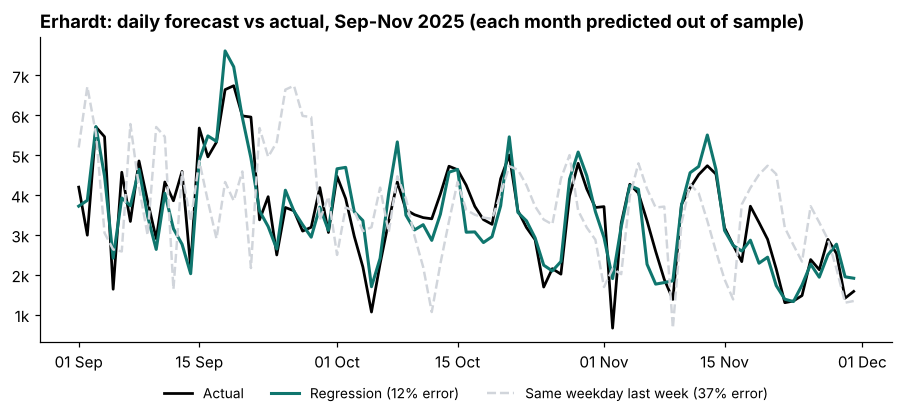

In [15]:
show = pred[(pred["station"] == "Erhardt") & (pred["month"].between(9, 11))]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(show["date"], show["total"], color="black", lw=1.8, label="Actual")
ax.plot(show["date"], show["Regression"], color="#0f766e", lw=2, label=f"Regression ({wape(show, 'Regression'):.0%} error)")
ax.plot(show["date"], show["Same weekday last week"], color=LIGHT, lw=1.6, ls="--",
        label=f"Same weekday last week ({wape(show, 'Same weekday last week'):.0%} error)")
ax.yaxis.set_major_formatter(thousands)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("Erhardt: daily forecast vs actual, Sep-Nov 2025 (each month predicted out of sample)")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
fig.savefig(IMG / "06_forecast.png")
plt.show()

**Result:** both models cut the error by more than half compared with the "same weekday last week" baseline (about 16% vs 36%). That baseline is thrown off every time the weather changes.

**XGBoost and the regression are tied overall, and I'd still pick the regression.** XGBoost does better in some summer months but has a much worse worst case: 29% error in December against the regression's 19%. With under a year of history, a tree model can't extrapolate to conditions it hasn't seen. The regression's simple structure (one temperature curve, one rain curve) carries over better, and it's easy to explain to a stakeholder. With several years of data, I'd revisit this choice.

December is the hardest month for both models, because the Christmas pattern isn't in the training data until it happens. Adding 2024 data would fix exactly that.

## 6. Takeaways

1. **Plan for a 2.6× seasonal swing.** Path maintenance and winter service matter most in the months when commuters are the only riders left.
2. **Rain costs about 7% of the year's trips**, and even light rain costs 9% on the day. Covered parking and good drainage on the busiest routes would protect the most trips.
3. **Treat Olympia and Erhardt as leisure corridors.** They stay busy on weekends and summer evenings and spike with events, so event planning should include cycle traffic.
4. **Counters double as event sensors.** The 10 km run and the Sommernachtstraum both left clear fingerprints. Comparing actuals against the forecast would flag closures or broken counters automatically.
5. **Check the Arnulf counter.** It records 94% of traffic in one direction, which the data owner should confirm is by design.

**Limitations:** one year of data and five counters, so this describes these routes rather than all of Munich. Weather comes from a single station. The event explanations for April and 16 July are still open.